In [1]:
import pandas as pd
import numpy as np

import scipy.stats as stats

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer


In [2]:
df = pd.read_csv("train.csv", usecols=["Age", "Fare", "Survived"])
df.head()


,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [3]:
print(df.isnull().sum())

# impute Age safely (even if no missing)
df["Age"] = df["Age"].fillna(df["Age"].mean())

print("\nAfter filling Age:")
print(df.isnull().sum())


Survived      0
Age         177
Fare          0
dtype: int64

After filling Age:
Survived    0
Age         0
Fare        0
dtype: int64


In [4]:
X = df[["Age", "Fare"]]
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

X_train.head()


,Age,Fare
331,45.5,28.5000
733,23.0,13.0000
382,32.0,7.9250
704,26.0,7.8542
813,6.0,31.2750


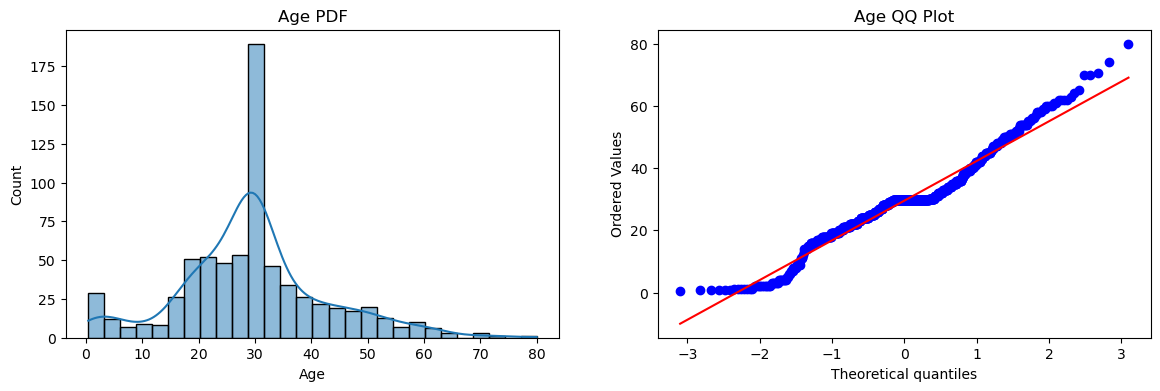

In [5]:
plt.figure(figsize=(14,4))

plt.subplot(121)
sns.histplot(X_train["Age"], kde=True)
plt.title("Age PDF")

plt.subplot(122)
stats.probplot(X_train["Age"], dist="norm", plot=plt)
plt.title("Age QQ Plot")

plt.show()


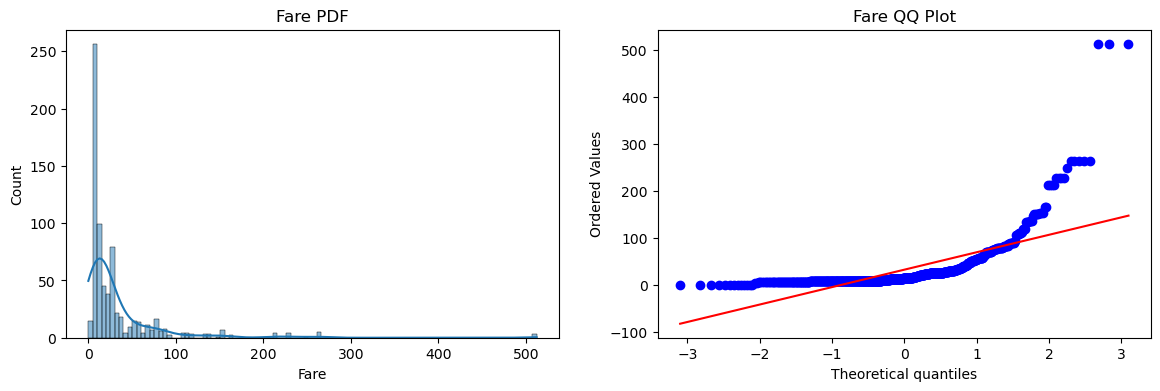

In [6]:
plt.figure(figsize=(14,4))

plt.subplot(121)
sns.histplot(X_train["Fare"], kde=True)
plt.title("Fare PDF")

plt.subplot(122)
stats.probplot(X_train["Fare"], dist="norm", plot=plt)
plt.title("Fare QQ Plot")

plt.show()


In [7]:
clf_lr = LogisticRegression(max_iter=1000)
clf_dt = DecisionTreeClassifier(random_state=42)

clf_lr.fit(X_train, y_train)
clf_dt.fit(X_train, y_train)

y_pred_lr = clf_lr.predict(X_test)
y_pred_dt = clf_dt.predict(X_test)

print("✅ Accuracy LR (no transform):", accuracy_score(y_test, y_pred_lr))
print("✅ Accuracy DT (no transform):", accuracy_score(y_test, y_pred_dt))


✅ Accuracy LR (no transform): 0.6480446927374302
✅ Accuracy DT (no transform): 0.659217877094972


In [8]:
trf_all = FunctionTransformer(func=np.log1p)

X_train_all_log = trf_all.fit_transform(X_train)
X_test_all_log = trf_all.transform(X_test)

clf_lr2 = LogisticRegression(max_iter=1000)
clf_dt2 = DecisionTreeClassifier(random_state=42)

clf_lr2.fit(X_train_all_log, y_train)
clf_dt2.fit(X_train_all_log, y_train)

y_pred_lr2 = clf_lr2.predict(X_test_all_log)
y_pred_dt2 = clf_dt2.predict(X_test_all_log)

print("✅ Accuracy LR (log on Age+Fare):", accuracy_score(y_test, y_pred_lr2))
print("✅ Accuracy DT (log on Age+Fare):", accuracy_score(y_test, y_pred_dt2))


✅ Accuracy LR (log on Age+Fare): 0.6815642458100558
✅ Accuracy DT (log on Age+Fare): 0.664804469273743


In [9]:
X_all_log = trf_all.fit_transform(X)

clf_lr3 = LogisticRegression(max_iter=1000)
clf_dt3 = DecisionTreeClassifier(random_state=42)

print("✅ CV Accuracy LR (Age+Fare log):", np.mean(cross_val_score(clf_lr3, X_all_log, y, scoring="accuracy", cv=10)))
print("✅ CV Accuracy DT (Age+Fare log):", np.mean(cross_val_score(clf_dt3, X_all_log, y, scoring="accuracy", cv=10)))


✅ CV Accuracy LR (Age+Fare log): 0.678027465667915
✅ CV Accuracy DT (Age+Fare log): 0.6577028714107367


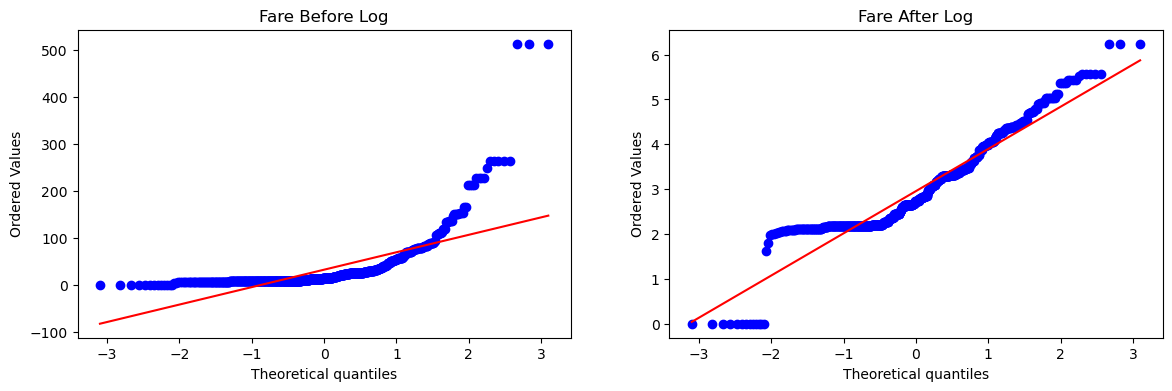

In [11]:
plt.figure(figsize=(14,4))

plt.subplot(121)
stats.probplot(X_train["Fare"], dist="norm", plot=plt)
plt.title("Fare Before Log")

plt.subplot(122)
stats.probplot(X_train_all_log.to_numpy()[:, 1], dist="norm", plot=plt)  
plt.title("Fare After Log")

plt.show()



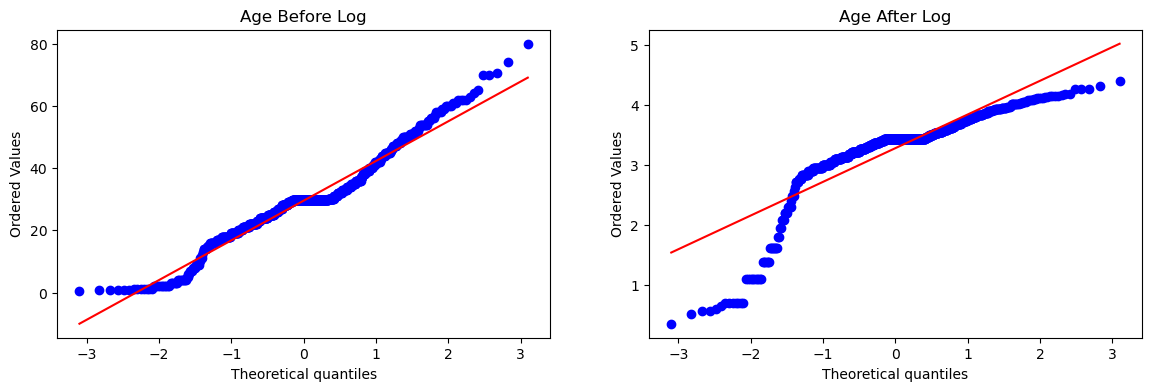

In [12]:
plt.figure(figsize=(14,4))

plt.subplot(121)
stats.probplot(X_train["Age"], dist="norm", plot=plt)
plt.title("Age Before Log")

plt.subplot(122)
stats.probplot(X_train_all_log.to_numpy()[:, 0], dist="norm", plot=plt)
plt.title("Age After Log")

plt.show()


In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

trf_fare_only = ColumnTransformer(
    transformers=[
        ("log_fare", FunctionTransformer(np.log1p), ["Fare"])
    ],
    remainder="passthrough"
)

X_train_fare_log = trf_fare_only.fit_transform(X_train)
X_test_fare_log = trf_fare_only.transform(X_test)

clf_lr = LogisticRegression(max_iter=1000)
clf_dt = DecisionTreeClassifier(random_state=42)

clf_lr.fit(X_train_fare_log, y_train)
clf_dt.fit(X_train_fare_log, y_train)

y_pred_lr = clf_lr.predict(X_test_fare_log)
y_pred_dt = clf_dt.predict(X_test_fare_log)

print("✅ Accuracy LR (Fare log only):", accuracy_score(y_test, y_pred_lr))
print("✅ Accuracy DT (Fare log only):", accuracy_score(y_test, y_pred_dt))


✅ Accuracy LR (Fare log only): 0.6703910614525139
✅ Accuracy DT (Fare log only): 0.659217877094972


In [14]:
from sklearn.model_selection import cross_val_score

X_fare_log_only = trf_fare_only.fit_transform(X)

clf_lr = LogisticRegression(max_iter=1000)
clf_dt = DecisionTreeClassifier(random_state=42)

print("✅ CV Accuracy LR (Fare log only):",
      np.mean(cross_val_score(clf_lr, X_fare_log_only, y, scoring="accuracy", cv=10)))

print("✅ CV Accuracy DT (Fare log only):",
      np.mean(cross_val_score(clf_dt, X_fare_log_only, y, scoring="accuracy", cv=10)))


✅ CV Accuracy LR (Fare log only): 0.6712609238451936
✅ CV Accuracy DT (Fare log only): 0.6621972534332085


In [15]:
from sklearn.model_selection import cross_val_score

X_fare_log_only = trf_fare_only.fit_transform(X)

clf_lr = LogisticRegression(max_iter=1000)
clf_dt = DecisionTreeClassifier(random_state=42)

print("✅ CV Accuracy LR (Fare log only):",
      np.mean(cross_val_score(clf_lr, X_fare_log_only, y, scoring="accuracy", cv=10)))

print("✅ CV Accuracy DT (Fare log only):",
      np.mean(cross_val_score(clf_dt, X_fare_log_only, y, scoring="accuracy", cv=10)))


✅ CV Accuracy LR (Fare log only): 0.6712609238451936
✅ CV Accuracy DT (Fare log only): 0.6621972534332085


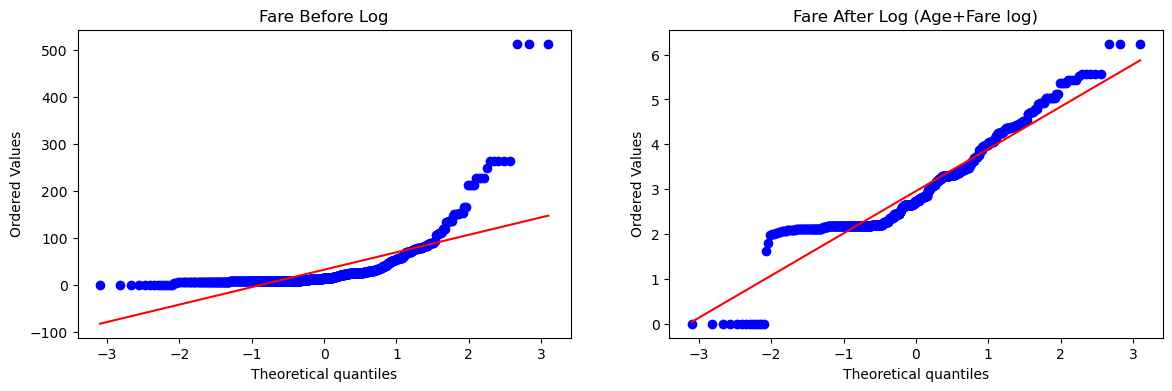

In [16]:
plt.figure(figsize=(14,4))

plt.subplot(121)
stats.probplot(X_train["Fare"], dist="norm", plot=plt)
plt.title("Fare Before Log")

plt.subplot(122)
# Agar X_train_all_log DataFrame hai to .to_numpy()
stats.probplot(X_train_all_log.to_numpy()[:, 1], dist="norm", plot=plt)
plt.title("Fare After Log (Age+Fare log)")

plt.show()


In [17]:
trf2 = ColumnTransformer(
    transformers=[
        ("log", FunctionTransformer(np.log1p), ["Fare"])
    ],
    remainder="passthrough"
)

X_train_transformed2 = trf2.fit_transform(X_train)
X_test_transformed2 = trf2.transform(X_test)

clf = LogisticRegression(max_iter=1000)
clf2 = DecisionTreeClassifier(random_state=42)

clf.fit(X_train_transformed2, y_train)
clf2.fit(X_train_transformed2, y_train)

y_pred_lr = clf.predict(X_test_transformed2)
y_pred_dt = clf2.predict(X_test_transformed2)

print("✅ Accuracy LR (Only Fare log):", accuracy_score(y_test, y_pred_lr))
print("✅ Accuracy DT (Only Fare log):", accuracy_score(y_test, y_pred_dt))


✅ Accuracy LR (Only Fare log): 0.6703910614525139
✅ Accuracy DT (Only Fare log): 0.659217877094972


In [18]:
X_transformed2 = trf2.fit_transform(X)

clf = LogisticRegression(max_iter=1000)
clf2 = DecisionTreeClassifier(random_state=42)

print("✅ CV LR (Only Fare log):", np.mean(cross_val_score(clf, X_transformed2, y, scoring="accuracy", cv=10)))
print("✅ CV DT (Only Fare log):", np.mean(cross_val_score(clf2, X_transformed2, y, scoring="accuracy", cv=10)))


✅ CV LR (Only Fare log): 0.6712609238451936
✅ CV DT (Only Fare log): 0.6621972534332085


In [19]:
def apply_transform(transform):
    X_local = df[["Age", "Fare"]]
    y_local = df["Survived"]

    trf_local = ColumnTransformer(
        transformers=[
            ("fare_transform", FunctionTransformer(transform), ["Fare"])
        ],
        remainder="passthrough"
    )

    X_trans = trf_local.fit_transform(X_local)

    clf_local = LogisticRegression(max_iter=1000)

    print("✅ CV Accuracy:", np.mean(cross_val_score(clf_local, X_trans, y_local, scoring="accuracy", cv=10)))

    plt.figure(figsize=(14,4))

    plt.subplot(121)
    stats.probplot(X_local["Fare"], dist="norm", plot=plt)
    plt.title("Fare Before Transform")

    plt.subplot(122)
    stats.probplot(X_trans[:, 0], dist="norm", plot=plt)
    plt.title("Fare After Transform")

    plt.show()


✅ CV Accuracy: 0.6195131086142323


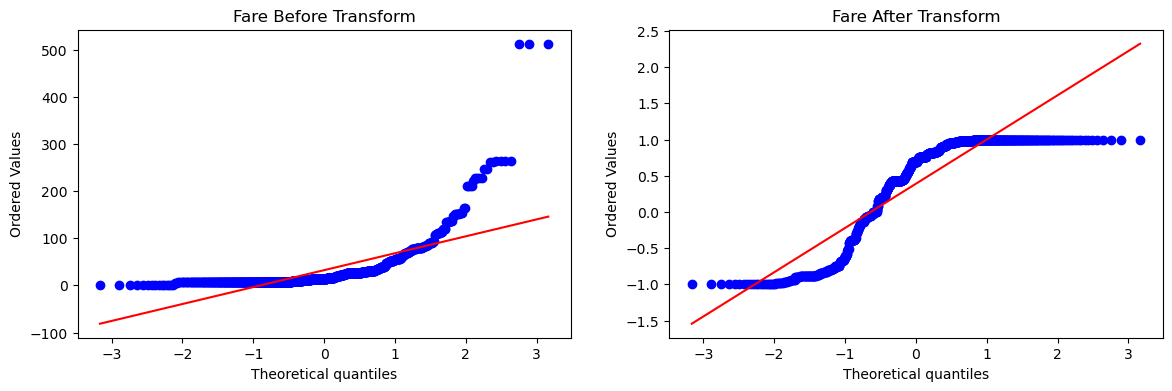

In [20]:
apply_transform(np.sin)


✅ CV Accuracy: 0.6611485642946316


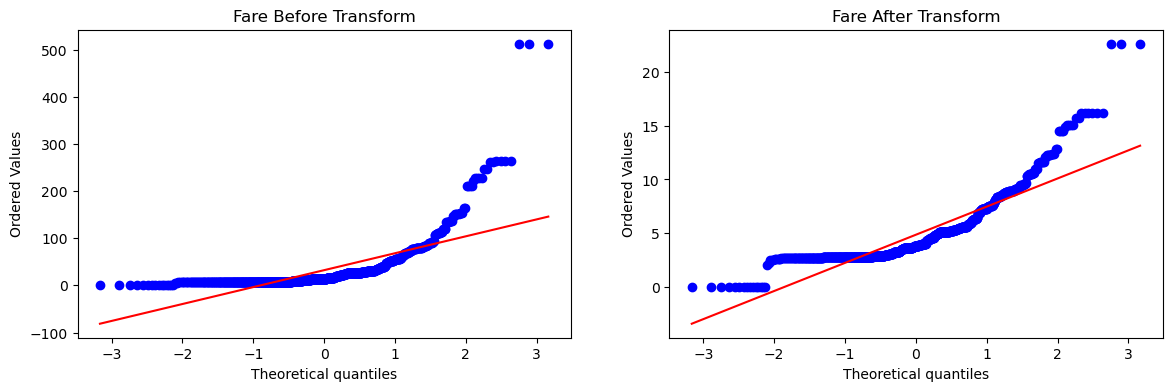

In [21]:
apply_transform(np.sqrt)


✅ CV Accuracy: 0.6712609238451936


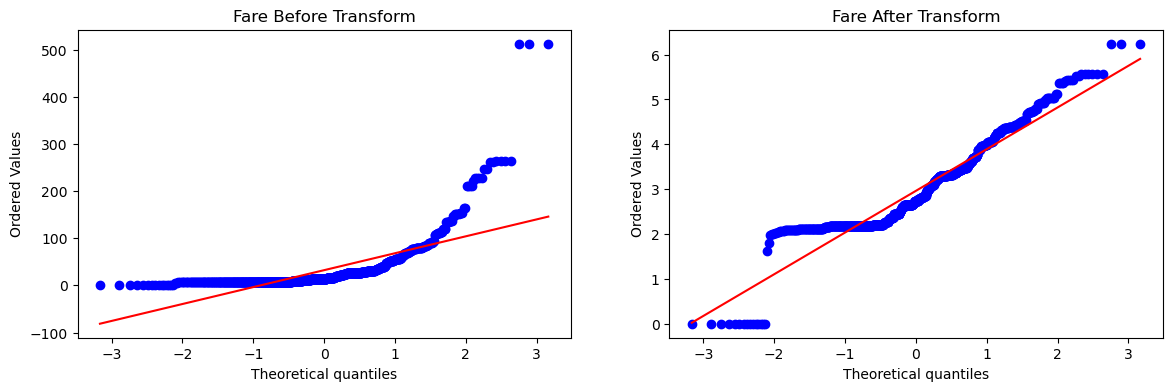

In [22]:
apply_transform(np.log1p)
